# PARTE 3 E 4: REGRESSÃO LOGÍSTICA E SVM

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

# PARTE 3: Regressão Logística

1. Utilize a base de dados construída no Trabalho 3 ‘risco_credito.pkl’, que possui 14 registros, para testar o algoritmo de Regressão Logística.

2. Faça o Encoder dos dados e, para facilitar, como fizemos na aula teórica, apague os registros que possuem a classe ‘moderado’. No total teremos 11 registros.

3. Treine o algoritmo de regressão logística e utilize o parâmetro ‘random_state =1’ para ter sempre o mesmo resultado.

4. Utilize o comando ‘.intercept_’ para ter o resultado do B0.
O resultado deve ser =-0.80828993

5. Utilize o comando ‘.coef_’ para ter o resultado dos demais parâmetros que deve ser:
array([[-0.76704533,  0.23906678, -0.47976059,  1.12186218]])

6. Agora utilize o comando ‘predict’ para fazer o teste do seu algoritmo com:

    a) história boa, dívida alta, garantias nenhuma, renda > 35
    (o resultado desse teste deve ser ‘baixo’)

    b) história ruim, dívida alta, garantias adequada, renda < 15
    (o resultado desse teste deve ser ‘alto’)

In [2]:
from sklearn.linear_model import LogisticRegression

### 1. Importar a base de dados 'risco_credito.pkl'

In [3]:
# 1. Importar a base de dados de risco de crédito salva na Parte 1 (14 registros)
# O .pkl guarda uma lista com 5 arrays, na mesma ordem em que foram salvos na Parte 1:
# historia, divida, garantias, renda e risco (a classe)
import pickle
with open('risco_credito.pkl', 'rb') as f:
    X_risco_credito_historia, X_risco_credito_divida, X_risco_credito_garantias, X_risco_credito_renda, y_risco_credito = pickle.load(f)

print(X_risco_credito_historia)
print(X_risco_credito_divida)
print(X_risco_credito_garantias)
print(X_risco_credito_renda)
print(y_risco_credito)

[2 1 1 1 1 1 2 2 0 0 0 0 0 2]
[0 0 1 1 1 1 1 1 1 0 0 0 0 0]
[1 1 1 1 1 0 1 0 1 0 1 1 1 1]
[0 1 1 2 2 2 0 2 2 2 0 1 2 1]
[0 0 2 0 1 1 0 2 1 1 0 2 1 0]


### 2. Encoder dos dados e remoção dos registros com classe 'moderado'

In [4]:
# 2. Encoder dos dados
# Os dados do .pkl já estão em número, porque o LabelEncoder foi aplicado na Parte 1.
# Aqui recriamos os mesmos LabelEncoders (com as mesmas categorias) para conseguir:
#   - converter texto -> número na hora de fazer o predict (item 6)
#   - converter número -> texto para mostrar o resultado como 'alto' / 'baixo'
# O LabelEncoder numera as categorias em ordem alfabética, por isso os números ficam iguais aos da Parte 1.
from sklearn.preprocessing import LabelEncoder

label_encoder_historia = LabelEncoder()
label_encoder_divida = LabelEncoder()
label_encoder_garantias = LabelEncoder()
label_encoder_renda = LabelEncoder()
label_encoder_risco = LabelEncoder()

label_encoder_historia.fit(['boa', 'desconhecida', 'ruim'])     # boa=0, desconhecida=1, ruim=2
label_encoder_divida.fit(['alta', 'baixa'])                     # alta=0, baixa=1
label_encoder_garantias.fit(['adequada', 'nenhuma'])            # adequada=0, nenhuma=1
label_encoder_renda.fit(['0_15', '15_35', 'acima_35'])          # 0_15=0, 15_35=1, acima_35=2
label_encoder_risco.fit(['alto', 'baixo', 'moderado'])          # alto=0, baixo=1, moderado=2

# Conferindo: voltando os números para texto (inverse_transform) tem que aparecer a base original
print(label_encoder_historia.inverse_transform(X_risco_credito_historia))
print(label_encoder_divida.inverse_transform(X_risco_credito_divida))
print(label_encoder_garantias.inverse_transform(X_risco_credito_garantias))
print(label_encoder_renda.inverse_transform(X_risco_credito_renda))
print(label_encoder_risco.inverse_transform(y_risco_credito))

['ruim' 'desconhecida' 'desconhecida' 'desconhecida' 'desconhecida'
 'desconhecida' 'ruim' 'ruim' 'boa' 'boa' 'boa' 'boa' 'boa' 'ruim']
['alta' 'alta' 'baixa' 'baixa' 'baixa' 'baixa' 'baixa' 'baixa' 'baixa'
 'alta' 'alta' 'alta' 'alta' 'alta']
['nenhuma' 'nenhuma' 'nenhuma' 'nenhuma' 'nenhuma' 'adequada' 'nenhuma'
 'adequada' 'nenhuma' 'adequada' 'nenhuma' 'nenhuma' 'nenhuma' 'nenhuma']
['0_15' '15_35' '15_35' 'acima_35' 'acima_35' 'acima_35' '0_15' 'acima_35'
 'acima_35' 'acima_35' '0_15' '15_35' 'acima_35' '15_35']
['alto' 'alto' 'moderado' 'alto' 'baixo' 'baixo' 'alto' 'moderado' 'baixo'
 'baixo' 'alto' 'moderado' 'baixo' 'alto']


In [5]:
# Juntar os 4 atributos em uma matriz X (cada linha = 1 cliente, cada coluna = 1 atributo),
# do mesmo jeito que foi feito na Parte 1 com np.column_stack
X_risco_credito = np.column_stack((
    X_risco_credito_historia,
    X_risco_credito_divida,
    X_risco_credito_garantias,
    X_risco_credito_renda
))

# Apagar os registros com classe 'moderado'.
# Por quê: como na aula teórica, a Regressão Logística é usada para separar 2 classes
# (a curva sigmoide dá a probabilidade de ser de uma classe ou da outra), então ficamos só com 'alto' e 'baixo'.

# np.where encontra as posições (linhas) onde o risco é 'moderado' (número 2)
indices_moderado = np.where(y_risco_credito == label_encoder_risco.transform(['moderado'])[0])[0]
print("Linhas com risco moderado:", indices_moderado)

# np.delete remove essas linhas; axis=0 indica que estamos removendo LINHAS (e não colunas)
X_risco_credito = np.delete(X_risco_credito, indices_moderado, axis=0)
y_risco_credito = np.delete(y_risco_credito, indices_moderado, axis=0)

print(X_risco_credito.shape)   # (11, 4) -> 11 registros e 4 atributos
print(y_risco_credito)         # sobraram só 0 (alto) e 1 (baixo)

Linhas com risco moderado: [ 2  7 11]
(11, 4)
[0 0 0 1 1 0 1 1 0 1 0]


### 3. Treinar o algoritmo de Regressão Logística

In [6]:
# 3. Criar o objeto da Regressão Logística
# random_state=1 -> fixa a "semente" de aleatoriedade, assim o resultado é sempre o mesmo
logistica_risco_credito = LogisticRegression(random_state=1)

# .fit é onde acontece o treinamento: o algoritmo procura os valores de B0, B1, B2, B3 e B4
# que melhor separam os clientes de risco 'alto' dos de risco 'baixo'
# 1º parâmetro: atributos (X)   2º parâmetro: classe (y)
logistica_risco_credito.fit(X_risco_credito, y_risco_credito)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",1
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following as

### 4. Resultado do B0 (intercept_)

In [7]:
# 4. Equação da Regressão Logística:
#    y = B0 + B1*historia + B2*divida + B3*garantias + B4*renda
#    probabilidade = 1 / (1 + e^(-y))   -> função sigmoide, sempre dá um valor entre 0 e 1
#    se a probabilidade for maior que 0.5 o cliente vai para a classe 1 ('baixo'), senão vai para a classe 0 ('alto')
#
# B0 (intercepto) é o valor "de partida" da equação, quando todos os atributos valem 0
print(logistica_risco_credito.intercept_)

# Esperado: -0.80828993
# Pode aparecer uma diferença pequena na 4ª casa decimal (ex: -0.80855152), porque o solver padrão (lbfgs)
# para de calcular quando chega "perto o suficiente" do melhor valor, e isso muda um pouco entre versões do sklearn.

[-0.80855152]


### 5. Resultado dos demais parâmetros (coef_)

In [8]:
# 5. Demais parâmetros: B1, B2, B3 e B4 (um peso para cada atributo, na mesma ordem das colunas de X)
#    [historia, divida, garantias, renda]
print(logistica_risco_credito.coef_)

# Esperado: [[-0.76704533,  0.23906678, -0.47976059,  1.12186218]]
# Como ler os pesos:
#   peso positivo puxa o cliente para a classe 1 ('baixo'), peso negativo puxa para a classe 0 ('alto')
#   renda (1.12)      -> maior peso: quanto maior a renda (0_15=0 ... acima_35=2), maior a chance de risco baixo
#   historia (-0.77)  -> boa=0 e ruim=2, então quanto pior a história, maior a chance de risco alto
#   garantias (-0.48) -> nenhuma=1 puxa para risco alto, adequada=0 não pesa contra
#   divida (0.24)     -> menor peso: dívida baixa=1 ajuda um pouco a ter risco baixo

[[-0.76706797  0.23921064 -0.47989768  1.12196145]]


### 6. Testar o algoritmo com o predict

In [9]:
# 6. Fazer a previsão com .predict
# O transform dos encoders converte o texto no mesmo número usado no treinamento

# a) história boa, dívida alta, garantias nenhuma, renda > 35
previsao1 = logistica_risco_credito.predict([[
    label_encoder_historia.transform(["boa"])[0],
    label_encoder_divida.transform(["alta"])[0],
    label_encoder_garantias.transform(["nenhuma"])[0],
    label_encoder_renda.transform(["acima_35"])[0]
]])

# inverse_transform faz o caminho contrário: número -> texto ('alto' / 'baixo')
print("Previsão a):", previsao1, label_encoder_risco.inverse_transform(previsao1))   # esperado: baixo


# b) história ruim, dívida alta, garantias adequada, renda < 15
previsao2 = logistica_risco_credito.predict([[
    label_encoder_historia.transform(["ruim"])[0],
    label_encoder_divida.transform(["alta"])[0],
    label_encoder_garantias.transform(["adequada"])[0],
    label_encoder_renda.transform(["0_15"])[0]
]])

print("Previsão b):", previsao2, label_encoder_risco.inverse_transform(previsao2))   # esperado: alto

Previsão a): [1] ['baixo']
Previsão b): [0] ['alto']


##Algoritmo de Regressão Logística para uma base de dados maior (Credit Data)

7. Agora aplique a Regressão Logística na base de dados ‘credit.pkl’. De quanto foi a taxa de acerto?

8. O resultado com a base de dados ‘credit.pkl’ é melhor que os resultados do Naive Bayes e das Florestas Aleatórias? Descreva sua análise de resultados (observe que para isso você deverá visualizar os resultados da Matriz de Confusão, acurácia, precisão e recall).

### 7. Regressão Logística na base 'credit.pkl'

In [10]:
# 7. Abrir a base credit.pkl (a mesma usada na Parte 2)
# Ela já vem dividida em treinamento (1500 registros) e teste (500 registros),
# com os atributos ['income', 'age', 'loan'] já padronizados (todos na mesma escala).
# Classe: 0 = paga a dívida, 1 = não paga
with open('content/credit.pkl', 'rb') as f:
  X_credit_treinamento, y_credit_treinamento, X_credit_teste, y_credit_teste = pickle.load(f)

print(X_credit_treinamento.shape, y_credit_treinamento.shape)
print(X_credit_teste.shape, y_credit_teste.shape)

(1500, 3) (1500,)
(500, 3) (500,)


In [11]:
# Criar e treinar a Regressão Logística com os dados de TREINAMENTO
# random_state=1 pelo mesmo motivo de antes: sempre o mesmo resultado
logistica_credito = LogisticRegression(random_state=1)
logistica_credito.fit(X_credit_treinamento, y_credit_treinamento)

# Fazer a previsão com os dados de TESTE (clientes que o modelo não viu no treinamento)
previsoes = logistica_credito.predict(X_credit_teste)

print("Previsões:")
print(previsoes)

print("\nValores reais:")
print(y_credit_teste)

Previsões:
[1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1
 0 0 0 0 0 0 0 1 1 1 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 0 0 0 1 0 0 1 0
 0 1 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 1 0 0 0 0 0 1 0
 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0
 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0
 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 1 0
 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 1 1
 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 1 0 1 0 0 0 1 0 0 0 1 0 1 0 0 1 0 0
 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0
 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0
 0 0 0 0 0 1 0

In [12]:
from sklearn.metrics import accuracy_score

# accuracy_score compara as previsões com os valores reais e devolve a porcentagem de acertos
acuracia = accuracy_score(y_credit_teste, previsoes)

print("Acurácia:", acuracia)
print("A taxa de acerto da Regressão Logística foi de 94,6% (acertou 473 dos 500 clientes da base de teste).")

Acurácia: 0.946
A taxa de acerto da Regressão Logística foi de 94,6% (acertou 473 dos 500 clientes da base de teste).


### 8. Comparação com o Naive Bayes e as Florestas Aleatórias

a) Matriz de Confusão da Regressão Logística

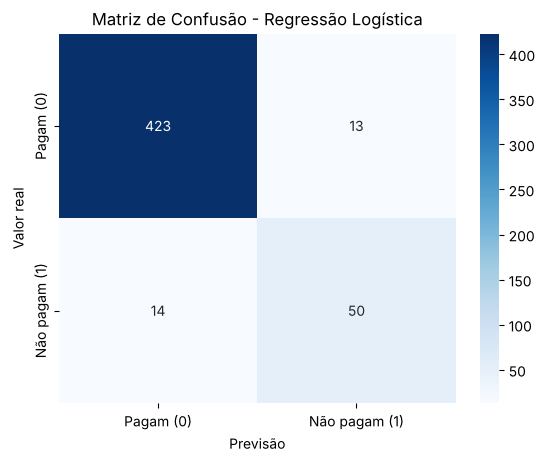

In [13]:
from sklearn.metrics import confusion_matrix

# Matriz de confusão: linhas = valor real, colunas = previsão do modelo
matriz_confusao = confusion_matrix(y_credit_teste, previsoes)

sns.heatmap(
	matriz_confusao,
	annot=True,
	fmt='d',
	cmap='Blues',
	xticklabels=['Pagam (0)', 'Não pagam (1)'],
	yticklabels=['Pagam (0)', 'Não pagam (1)']
)

plt.xlabel('Previsão')
plt.ylabel('Valor real')
plt.title('Matriz de Confusão - Regressão Logística')
plt.show()

b) Precision e recall da Regressão Logística (classification_report)

In [14]:
from sklearn.metrics import classification_report

# precision: dos clientes que o modelo disse ser de uma classe, quantos realmente são
# recall: dos clientes que realmente são de uma classe, quantos o modelo conseguiu encontrar
print(classification_report(y_credit_teste, previsoes))

              precision    recall  f1-score   support

           0       0.97      0.97      0.97       436
           1       0.79      0.78      0.79        64

    accuracy                           0.95       500
   macro avg       0.88      0.88      0.88       500
weighted avg       0.95      0.95      0.95       500



c) Comparando os algoritmos na mesma base 'credit.pkl'

In [15]:
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score

# Para comparar de forma justa, os outros algoritmos são treinados na MESMA base credit.pkl,
# com os mesmos parâmetros usados nas Partes 1 e 2
modelos = {
    'Naive Bayes': GaussianNB(),
    'Random Forest (10 árvores)': RandomForestClassifier(n_estimators=10, criterion='entropy', random_state=0),
    'Random Forest (100 árvores)': RandomForestClassifier(n_estimators=100, criterion='entropy', random_state=0),
    'Regressão Logística': LogisticRegression(random_state=1)
}

resultados = []
for nome, modelo in modelos.items():
    modelo.fit(X_credit_treinamento, y_credit_treinamento)
    previsoes_modelo = modelo.predict(X_credit_teste)
    matriz = confusion_matrix(y_credit_teste, previsoes_modelo)

    resultados.append([
        nome,
        accuracy_score(y_credit_teste, previsoes_modelo),
        precision_score(y_credit_teste, previsoes_modelo),   # precision da classe 1 (não pagam)
        recall_score(y_credit_teste, previsoes_modelo),      # recall da classe 1 (não pagam)
        matriz[0][1],   # pagantes classificados errado como não pagantes
        matriz[1][0]    # não pagantes classificados errado como pagantes
    ])

comparacao = pd.DataFrame(resultados, columns=[
    'Algoritmo', 'Acurácia', 'Precision (não pagam)', 'Recall (não pagam)',
    'Pagam -> previsto não pagam', 'Não pagam -> previsto pagam'
])
comparacao.round(3)

,Algoritmo,Acurácia,Precision (não pagam),Recall (não pagam),Pagam -> previsto não pagam,Não pagam -> previsto pagam
0,Naive Bayes,0.938,0.837,0.641,8,23
1,Random Forest (10 árvores),0.968,0.929,0.812,4,12
2,Random Forest (100 árvores),0.982,0.951,0.906,3,6
3,Regressão Logística,0.946,0.794,0.781,13,14


d) Análise dos resultados

Na matriz de confusão, a Regressão Logística classificou corretamente 423 clientes que pagam e 50 que não pagam. Errou 13 clientes que pagam (classificados como não pagantes) e 14 que não pagam (classificados como pagantes), totalizando 27 erros em 500 registros, o que dá a acurácia de 94,6%.

Comparando com o Naive Bayes (93,8%), a Regressão Logística foi um pouco melhor. A maior diferença está no recall dos clientes que não pagam: a Regressão Logística encontrou 78% deles (50 de 64), enquanto o Naive Bayes encontrou só 64% (41 de 64). Em compensação, a precision da Regressão Logística ficou menor (79% contra 84%), porque ela marcou mais bons pagadores como não pagantes (13 contra 8).

Comparando com as Florestas Aleatórias, a Regressão Logística foi pior. A Random Forest teve 96,8% de acurácia com 10 árvores e 98,2% com 100 árvores. Com 100 árvores, a precision para quem não paga foi de 95% e o recall de 91%, errando só 9 clientes no total. Isso acontece porque a Regressão Logística separa as classes com uma única linha reta (fronteira linear), enquanto as árvores fazem vários cortes nos atributos (os splits vistos na aula de Árvores de Decisão) e conseguem separar regiões mais complexas dos dados.

Conclusão: na base credit.pkl a Regressão Logística é melhor que o Naive Bayes, mas não é melhor que as Florestas Aleatórias. Para o banco, o erro mais caro é aprovar quem não vai pagar, e nesse ponto a Random Forest com 100 árvores errou 6 clientes, a Regressão Logística 14 e o Naive Bayes 23.

#PARTE 4: SVM

1. Aplique o algoritmo SVM na base de dados ‘credit.pkl’.
2. Inicialmente treine o SVM com kernel linear, valor do parâmetro C = 1.0 e ‘random_state =1’
3. Utilize o comando do sklearn accuray_score para calcular a acurácia do seu algoritmo. O resultado deve ser 0.946
4. Teste os demais kernels e anote os resultados. Qual o melhor kernel para a sua base de dados?
    * Polinomial
    * Sigmoide
    * rbf
5. Aumente o valor do parâmetro C aplicado ao melhor kernel e verifique se há mudanças no resultado do seu SVM.
6. O Grid Search (pesquisa em grade) é uma técnica utilizada para melhorar a precisão e a generalização dos modelos de aprendizado de máquina. Ela é usada para realizar ajustes de hiperparâmetros durante o treinamento de um modelo. O grid search automatiza o processo de encontrar hiperparâmetros ideais, economizando esforço humano em comparação com o ajuste manual, mas pode até ser mais custoso do ponto de vista de desempenho, pois testa todas as combinações possíveis e retorna a que obteve melhor desempenho.
Agora, aplique o GridSearch do Scikit-Learn (https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html) para ajudar a identificar os melhores hiperparâmetros para o seu modelo. Qual foi a melhor combinação de hiperparâmetros encontrada? O modelo com melhor desempenho foi obtido com os parâmetros ajustados manualmente ou com o GridSearch?

In [16]:
from sklearn.svm import SVC

## Base de Dados Credit Data

# Análise dos resultados dos 4 algoritmos utilizados:

6. O resultado do SVM é melhor que os resultados do Naive Bayes, Florestas Aleatórias e Regressão Logística? Descreva sua análise de resultados (observe que para isso você deverá visualizar os resultados da Matriz de Confusão, acurácia, precisão e recall).